In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score, adjusted_rand_score

форма данных: (178, 13)
истинных классов: 3
найдено кластеров: 0
точек шума (метка -1): 178 из 178
Silhouette Score не определён: найдено меньше 2 кластеров
Adjusted Rand Index: 0.000


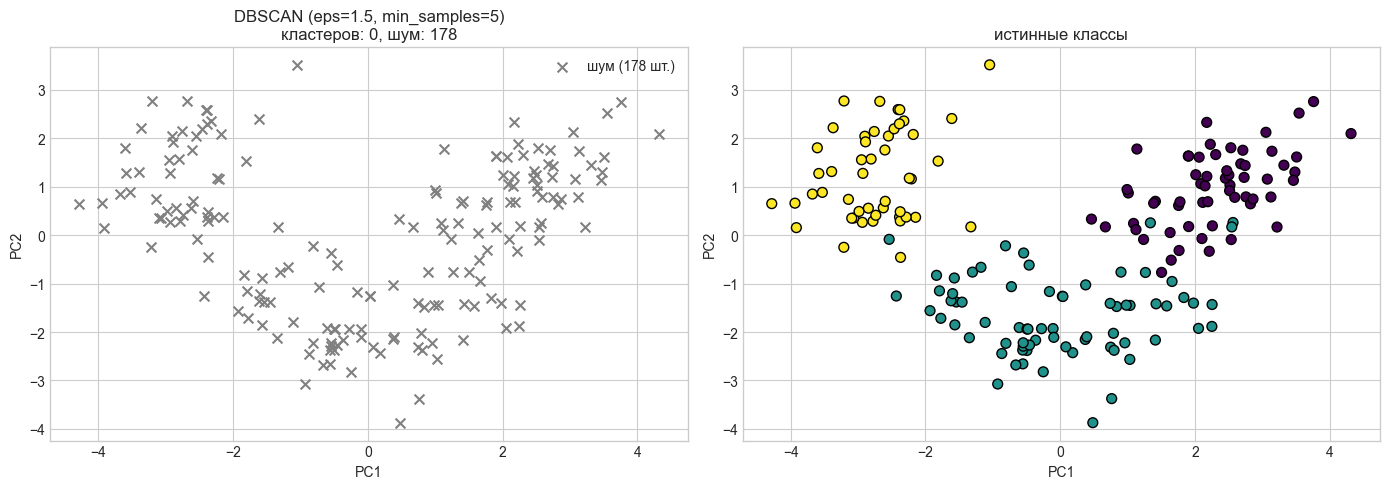

средние значения признаков по кластерам:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
cluster,,,,,,,,,,,,,



топ-5 маркерных признаков:
alcohol             NaN
malic_acid          NaN
ash                 NaN
alcalinity_of_ash   NaN
magnesium           NaN
dtype: float64


In [ ]:
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('viridis')
np.random.seed(42)


wine = load_wine()
X_wine = wine.data
y_true_wine = wine.target

X_wine_scaled = StandardScaler().fit_transform(X_wine)

pca = PCA(n_components=2, random_state=42)
X_wine_pca = pca.fit_transform(X_wine_scaled)

print(f"форма данных: {X_wine_scaled.shape}")
print(f"истинных классов: {len(np.unique(y_true_wine))}")

dbscan_wine = DBSCAN(eps=1.5, min_samples=5)
labels_db_wine = dbscan_wine.fit_predict(X_wine_scaled)

n_clusters = len(set(labels_db_wine)) - (1 if -1 in labels_db_wine else 0)
n_noise = np.sum(labels_db_wine == -1)

print(f"найдено кластеров: {n_clusters}")
print(f"точек шума (метка -1): {n_noise} из {len(labels_db_wine)}")

mask = labels_db_wine != -1

if n_clusters >= 2:
    sil = silhouette_score(X_wine_scaled[mask], labels_db_wine[mask])
    print(f"Silhouette Score (без шума): {sil:.3f}")
else:
    print("Silhouette Score не определён: найдено меньше 2 кластеров")

ari = adjusted_rand_score(y_true_wine, labels_db_wine)
print(f"Adjusted Rand Index: {ari:.3f}")

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
noise_mask = labels_db_wine == -1

plt.scatter(
    X_wine_pca[~noise_mask, 0], X_wine_pca[~noise_mask, 1],
    c=labels_db_wine[~noise_mask], cmap='viridis', s=50, edgecolor='k'
)
if noise_mask.any():
    plt.scatter(
        X_wine_pca[noise_mask, 0], X_wine_pca[noise_mask, 1],
        c='gray', marker='x', s=50, label=f'шум ({n_noise} шт.)'
    )
plt.title(f'DBSCAN (eps=1.5, min_samples=5)\nкластеров: {n_clusters}, шум: {n_noise}')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.legend()

plt.subplot(1, 2, 2)
plt.scatter(
    X_wine_pca[:, 0], X_wine_pca[:, 1],
    c=y_true_wine, cmap='viridis', s=50, edgecolor='k'
)
plt.title('истинные классы')
plt.xlabel('PC1')
plt.ylabel('PC2')

plt.tight_layout()
plt.show()

df_wine = pd.DataFrame(X_wine, columns=wine.feature_names)
df_wine['cluster'] = labels_db_wine

cluster_profiles = df_wine[df_wine['cluster'] != -1].groupby('cluster').mean()
print("средние значения признаков по кластерам:")
display(cluster_profiles)

feature_variance = cluster_profiles.var(axis=0).sort_values(ascending=False)
print("\nтоп-5 маркерных признаков:")
print(feature_variance.head(5))

In [4]:
# %% [Cell 7] (Опционально) Перебор eps для DBSCAN
for eps in [0.5, 1.0, 1.5, 2.0, 2.5, 3.0]:
    labels = DBSCAN(eps=eps, min_samples=5).fit_predict(X_wine_scaled)
    n_cl = len(set(labels)) - (1 if -1 in labels else 0)
    n_nz = np.sum(labels == -1)
    ari = adjusted_rand_score(y_true_wine, labels)
    print(f"eps={eps:.1f} | кластеров={n_cl} | шум={n_nz:3d} | ARI={ari:.3f}")

eps=0.5 | кластеров=0 | шум=178 | ARI=0.000
eps=1.0 | кластеров=0 | шум=178 | ARI=0.000
eps=1.5 | кластеров=0 | шум=178 | ARI=0.000
eps=2.0 | кластеров=5 | шум= 85 | ARI=0.220
eps=2.5 | кластеров=1 | шум= 24 | ARI=0.005
eps=3.0 | кластеров=1 | шум= 11 | ARI=-0.006
